# Introduction to Quantitative Biology — Assignment
## A genetic switch that decides: the toggle switch of phage λ

**Group:** `name 1` · `name 2` · `name 3`

**Deadline: <span style="color:red">Sunday 8 November 2026 at 23:59</span>.** One notebook (the
`.ipynb` file) per group, sent by email to luca.ciandrini@umontpellier.fr with the subject
**"Project qbio 1"**.

**How it is assessed.** The group writes the notebook together. Then each member has a short
**individual oral**, and must be able to explain *any* part of the notebook — the equations, the
code and the figures — not only the part they wrote. If the discussion leads there, the oral may
also include questions on Lectures 1–4.

**Rules.**
- Every figure has labelled axes and is followed by a few sentences saying what it shows.
- The notebook must run from top to bottom (*Kernel → Restart & Run All*) without errors.
- Use `numpy`, `matplotlib`, `scipy.integrate.solve_ivp` and, if you want, `scipy.optimize.brentq`.
  You may reuse any function from the class notebooks (for example `gillespie` from Lecture 4):
  say where it comes from.
- When you give a number, give it with the code that computed it.

**Reading.** Alon, *An Introduction to Systems Biology*, Section 5.1.2, pp. 80–83
(`Intro_SysBio_Ch5.pdf`). Optional: T. S. Gardner, C. R. Cantor, J. J. Collins, *Construction of
a genetic toggle switch in Escherichia coli*, Nature **403**, 339 (2000).

---
## Introduction

In Lecture 3 a gene that activates itself had two stable states, and could remember a signal. A
switch can also be built with **two** genes: X represses Y and Y represses X. If X is high, Y is
repressed, so nothing represses X and X stays high. The opposite state, Y high and X low, is
stable for the same reason. Alon calls this double-negative loop a **toggle switch**: it expresses
either X or Y, not both.

Phage λ, a virus of *E. coli*, uses such a switch to choose between two ways of life (Alon,
pp. 82–83):

- **lysogeny**: the phage DNA is inserted in the bacterial chromosome and copied with it at every
  division. Only the repressor **X = cI** is expressed;
- **lysis**: the phage makes about a hundred new phages and bursts the cell open. The repressor
  **Y = Cro** is expressed.

When the DNA of the cell is damaged, a protein called RecA cleaves cI. X disappears faster, Y is
no longer repressed, and the phage switches to lysis.

We will study a **toy version** of this circuit: two proteins only, no mRNA, the same parameters
for both genes, and none of the further regulation that the real λ switch has. The questions:

1. How can two repressors make a switch with two stable states? *(Parts I–II)*
2. How much DNA damage, and for how long, does it take to flip the switch, and does the cell
   remember it? *(Part III)*
3. With a few tens of molecules, which way does a newly infected cell go, and how long does the
   memory last? *(Part IV)*

---
## Part I: The model

Let $X(t)$ and $Y(t)$ be the concentrations of the two repressors. Each is made from a promoter
that the other one represses, and each is removed (degradation and dilution) at rate $\alpha$:

$$\frac{dX}{dt} = \frac{\beta}{1 + (Y/K)^n} - \alpha X, \qquad
  \frac{dY}{dt} = \frac{\beta}{1 + (X/K)^n} - \alpha Y .$$

### Question 1
In Lecture 2 we wrote the input function of a repressor $X$ as $f(X) = \beta K^n/(K^n + X^n)$.
(a) Show that the production term of $X$ above is the same function, with $Y$ as the repressor.
(b) Say in one sentence each what $\beta$, $K$, $n$ and $\alpha$ mean, and give their units.

**Your answer**

**Derivation of the production term**

From Lecture 2, the repression function is

$$
f(x)=\frac{\beta K^n}{K^n+x^n}.
$$

In the report, the equation for $X$ is written as

$$
\frac{dX}{dt}
=
\frac{\beta}{1+\left(\frac{Y}{K}\right)^n}
-\alpha X.
$$

We can rewrite the production term as

$$
\frac{\beta}{1+\frac{Y^n}{K^n}}.
$$

Multiplying the numerator and denominator by $K^n$ gives

$$
\frac{\beta K^n}{K^n+Y^n}.
$$

Therefore,

$$
\frac{dX}{dt}
=
\frac{\beta K^n}{K^n+Y^n}
-\alpha X.
$$

So the production term for protein $X$ used in the report has the same form as the repression function introduced in Lecture 2.

**Question 1B**

- **$\beta$**: coefficient for the rate of production of the protein.  
  Unit: $\mathrm{s^{-1}}$

- **$K$**: repression coefficient; the concentration of the repressor at which the promoter operates at half of its maximum rate.  
  Unit: concentration units

- **$n$**: Hill coefficient.  
  Unit: dimensionless

- **$\alpha$**: coefficient for the rate of degradation of the protein. The degradation rate depends on the existing protein concentration.  
  Unit: $\mathrm{s^{-1}}$

> **Units.** We measure time in units of the protein lifetime $1/\alpha$ and concentrations in
> units of $K$. In these units $\alpha = 1$ and $K = 1$, and the model reads
>
> $$\frac{dX}{dt} = \frac{\beta}{1 + Y^n} - X, \qquad \frac{dY}{dt} = \frac{\beta}{1 + X^n} - Y .$$
>
> Unless a question says otherwise, $\beta = 5$ and $n = 2$.

### Question 2
Suppose $Y$ is held at a constant value. Where does $X$ go at long times? (This is the gene of
Lecture 1.) What is this value when $Y = 0$, and when $Y$ is much larger than $1$?

**$Y$ at a constant value**

Since $Y$ is constant, $Y^n$ is also constant. $\beta$ is constant as well, so the whole production term for $X$,

$$
\frac{\beta}{1+Y^n}
$$

becomes constant.

The degradation rate depends on the degradation coefficient $\alpha$, which is constant, and on the concentration of $X$. Therefore, at long times, production and degradation balance and $X$ approaches a constant steady-state value.

**For $Y = 0$**

The concentration of $X$ reaches its maximum possible steady-state value because the production term becomes

$$
\frac{\beta}{1+0^n} = \beta
$$

So the repression by $Y$ is absent.

**For $Y >> 1$**

The production of $X$ becomes very small because $Y^n$ becomes very large:

$$
\frac{\beta}{1+Y^n} \approx 0
$$

Therefore, the steady-state concentration of $X$ approaches $0$.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

beta = 5.0
n = 2

---
## Part II: Fixed points

> **Nullclines: a rate plot in two dimensions.** With one gene (Lecture 3) the fixed points were
> the crossings of the production and the removal curves. With two genes we draw, in the plane
> $(X, Y)$:
> - the **X-nullcline**, the curve on which $dX/dt = 0$;
> - the **Y-nullcline**, the curve on which $dY/dt = 0$.
>
> At a point where they cross, *neither* protein changes: it is a **fixed point**.
>
> The nullclines also tell us which way the cell moves. On one side of the X-nullcline the
> production of X is larger than its removal, so $X$ increases; on the other side $X$ decreases.
> These are the arrows of a Lecture 3 rate plot, here pointing right or left. In the same way, on
> either side of the Y-nullcline $Y$ increases or decreases: the arrows point up or down. Alon draws
> the toggle switch this way in Figure 5.9.

### Question 3
(a) Write the equations of the two nullclines.
(b) Plot them on the same $(X, Y)$ plane for $\beta = 5$, $n = 2$.
(c) How many fixed points are there? Say what each one means for the phage.

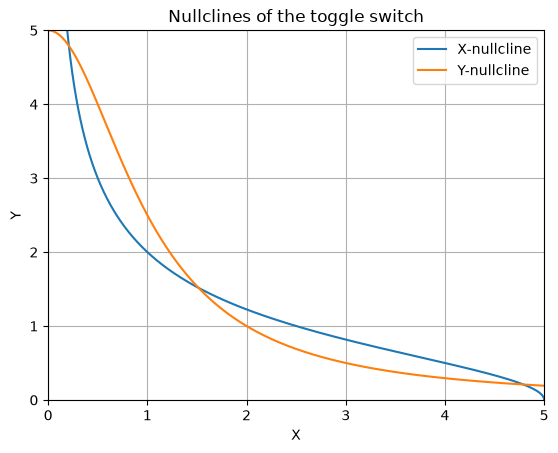

In [58]:
beta = 5.0
K = 1.0
n = 2

def nullcline_X(Y, beta=5, K=1, n=2):
    return beta * K**n / (K**n + Y**n)

def nullcline_Y(X, beta=5, K=1, n=2):
    return beta * K**n / (K**n + X**n)

# axes
X_vals = np.linspace(0, 5, 500)
Y_vals = np.linspace(0, 5, 500)

# Plotting the two curves
plt.plot(nullcline_X(Y_vals), Y_vals, label='X-nullcline')
plt.plot(X_vals, nullcline_Y(X_vals), label='Y-nullcline')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Nullclines of the toggle switch')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.legend()
plt.grid()

plt.show()



**Question 3C**


There are three fixed points, which lie at the intersection of the x and y nullclines:
- The first point is a stable state, where the concentration of Y is high and X is low. This indicates that the phage tends towards lysis.
- The second point is the unstable state, where the phage is held between lysis and lysogeny. In this case, any small deviation in either direction will lead to lysis or lysogeny respectively.
- The third point is a stable state, where the concentration of X is high and Y is low. This indicates that the phage tends towards lysogeny. 
...

### Question 4. Back to a one-dimensional rate plot
A fixed point lies on both nullclines. Substitute the Y-nullcline into the X-nullcline, and show
that the $X$ of a fixed point solves one equation in one unknown,

$$X = F(X), \qquad F(X) = \frac{\beta}{1 + \left(\dfrac{\beta}{1+X^n}\right)^{n}} .$$

(a) Plot $F(X)$ and the straight line $X$ on the same graph, as in a Lecture 3 rate plot.
(b) Find the fixed points numerically (for instance with `brentq` between two values of $X$ that
bracket a crossing), and the corresponding $Y$. Check that they agree with Question 3.
(c) In Lecture 3 the arrows of the rate plot gave the stability of each fixed point. Can we trust
them here? Hint: what did we assume about $Y$ when we replaced it by its nullcline?

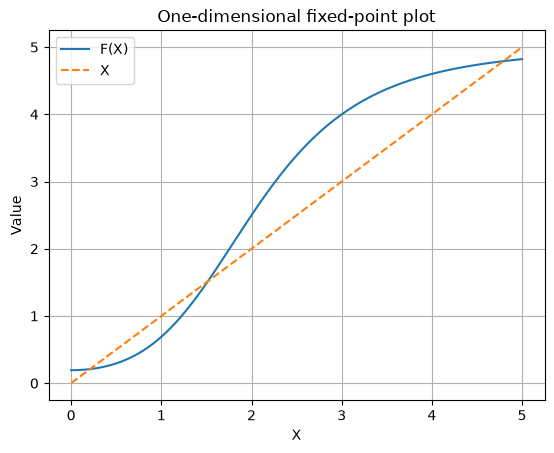

X = 0.2087, Y = 4.7913
X = 1.5160, Y = 1.5160
X = 4.7913, Y = 0.2087


In [ ]:
from scipy.optimize import brentq
 # f(X) in terms of X
def F(X):
    return beta / (1 + (beta / (1 + X**n))**n)

x_vals = np.linspace(0, 5, 500)
 #Plot F(X) in terms of X
plt.plot(x_vals, F(x_vals), label='F(X)')
plt.plot(x_vals, x_vals, label='X', linestyle='--')

plt.xlabel('X')
plt.ylabel('Value')
plt.title('One-dimensional fixed-point plot')
plt.legend()
plt.grid()
plt.show()

#Use brentq to find the fixed points 
def G(X):
    return F(X) - X

x1 = brentq(G, 0.1, 0.5)
x2 = brentq(G, 1.0, 2.0)
x3 = brentq(G, 4.0, 5.0)

for X in [x1, x2, x3]:
    Y = beta / (1 + X**n)
    print(f"X = {X:.4f}, Y = {Y:.4f}")



**Question 4**


We can trust the fixed points because at a fixed point both nullcline equations have to be satisfied.

However, we can not fully trust the stability from the 1D plot. When we substitute the $Y$-nullcline into the $X$ equation, we are basically assuming that $Y$ adjusts instantly to the value of X. 

$$\
Y=\frac{\beta}{1+X^n}.$$


So $Y$ is not constant, but we are assuming it immediately follows $X$. In the real 2D system, both $X$ and $Y$ change with time, so $Y$ does not always stay exactly on its nullcline. Because of this, the arrows in the 1D plot may not completely represent the real stability of the full system.

### Question 5. Why cooperativity matters
Repeat the plot of Question 3 for $n = 1, 2, 3$ (keeping $\beta = 5$). How does the number of
fixed points change, and why? Compare with Alon, Figure 5.10.

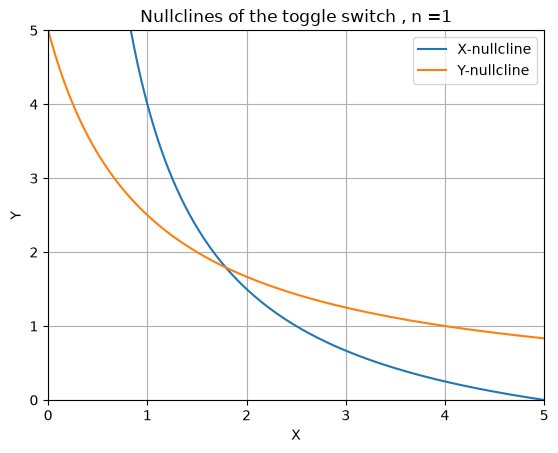

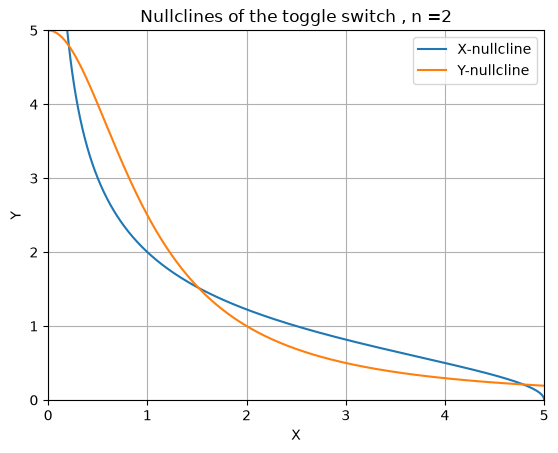

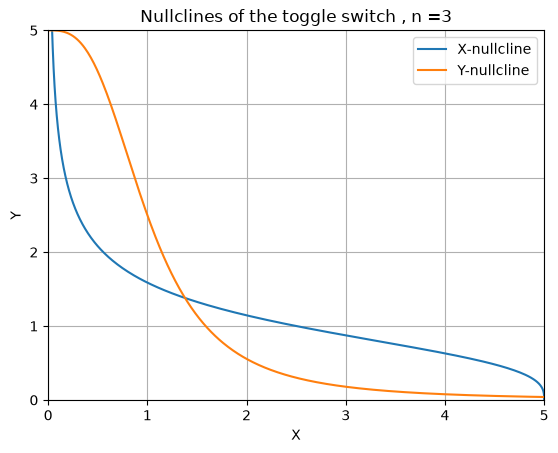

In [17]:
beta = 5.0
K = 1.0

# axes
X_vals = np.linspace(0, 5, 500)
Y_vals = np.linspace(0, 5, 500)
for i in range (1,4):
# Plotting the two curves
    plt.plot(nullcline_X(Y_vals, beta, K, i), Y_vals, label='X-nullcline')
    plt.plot(X_vals, nullcline_Y(X_vals, beta, K, i), label='Y-nullcline')

    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title(f'Nullclines of the toggle switch , n ={i}')
    plt.xlim(0, 5)
    plt.ylim(0, 5)
    plt.legend()
    plt.grid()

    plt.show()

- For $n=1$, there is no cooperativity in repression, so the repression functions are not strongly sigmoidal. Because of this, the two nullclines cross only once. The system therefore has only one fixed point and is monostable (Alon, Fig 5.10), with both $X$ and $Y$ reaching intermediate concentrations. Since there is only one stable state, the system cannot store memory.

- For $n \geq 2$, repression becomes cooperative and the nullclines become more sigmoidal. This allows them to cross three times, giving two stable fixed points and one unstable fixed point in the middle. The two stable points are basically the two states of the toggle switch, representing high $X$/low $Y$ or low $X$/high $Y$. This agrees with Alon (Figure 5.10).

- As $n$ increases further, the outer stable fixed points move closer to the axes. This means that one protein becomes more strongly expressed while the other becomes more strongly repressed, so the switch becomes sharper and more complete.

---
## Part III: Dynamics, and how DNA damage flips the switch

### Question 6. Trajectories in the plane
(a) Solve the equations with `solve_ivp` from at least four initial conditions of your choice,
up to $t = 15$, and draw the trajectories on top of the nullclines. Mark the fixed points.
(b) Which fixed points are stable, which unstable? Draw the line that separates the starting
points that end in lysogeny from those that end in lysis.
(c) A phage that has just infected a cell starts with no cI and no Cro: $X = Y = 0$. Where does
the model send it? Why? Do you believe this prediction?

*Optional: add the arrows $(dX/dt, dY/dt)$ on a grid with `plt.quiver`; the picture is then what
Alon calls the phase portrait.*

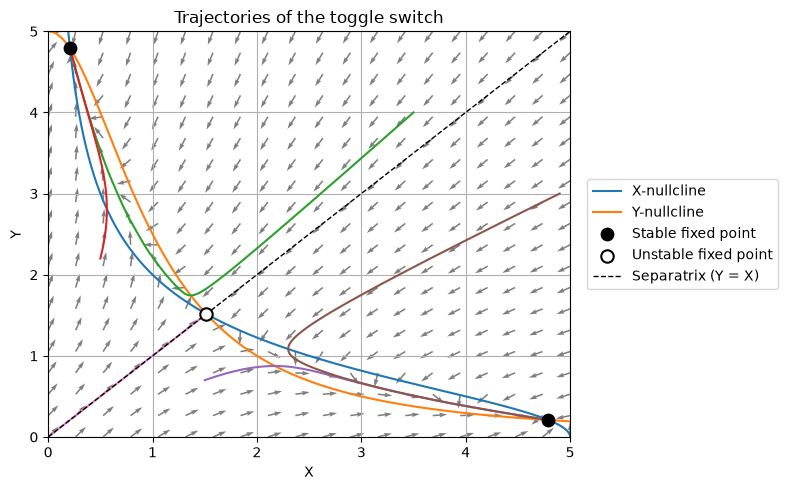

In [79]:
# Question 6

t_end = 15
num_points = 500

fig, ax = plt.subplots(figsize=(8, 5))

# Nullclines
ax.plot(nullcline_X(Y_vals, beta, K, n), Y_vals, label='X-nullcline')
ax.plot(X_vals, nullcline_Y(X_vals, beta, K, n), label='Y-nullcline')
#Fixed points
fp_X = np.array([x1, x2, x3])
fp_Y = beta / (1 + fp_X**n)

# Stable fixed points
ax.scatter(fp_X[[0, 2]], fp_Y[[0, 2]],
           s=80, c='black', zorder=5, label='Stable fixed point')

# Unstable fixed point
ax.scatter(fp_X[1], fp_Y[1],
           s=80, facecolors='white', edgecolors='black',
           linewidths=1.5, zorder=5, label='Unstable fixed point')

# Initial conditions
initial_conditions = [
    [3.5, 4.0],
    [0.5, 2.2],
    [1.5, 0.7],
    [4.9, 3.0],
    # related to part c
    [0.0, 0.0]
]

# Vector field for the phase portrait
X_grid, Y_grid = np.meshgrid(
    np.linspace(0, 5, 20),
    np.linspace(0, 5, 20)
)

dX = beta / (1 + Y_grid**n) - X_grid
dY = beta / (1 + X_grid**n) - Y_grid

# Normalize arrows so their directions are easy to see
magnitude = np.sqrt(dX**2 + dY**2)
dX_norm = dX / magnitude
dY_norm = dY / magnitude

ax.quiver(
    X_grid,
    Y_grid,
    dX_norm,
    dY_norm,
    alpha=0.5
)

def system(t, z):
    X, Y = z

    dXdt = beta / (1 + Y**n) - X
    dYdt = beta / (1 + X**n) - Y

    return [dXdt, dYdt]

# Plot trajectories
for initial in initial_conditions:
    sol = solve_ivp(
        system,
        [0, t_end],
        initial,
        t_eval=np.linspace(0, t_end, num_points)
    )

    x_traj = sol.y[0]
    y_traj = sol.y[1]

    ax.plot(x_traj, y_traj, lw=1.5)

# Line seperating lysogeny from lysis (separatrix)
ax.plot(X_vals, X_vals, 'k--', lw=1, label='Separatrix (Y = X)')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Trajectories of the toggle switch')
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.grid()

ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()

**Question 6B**

- Trajectories starting on one side of the diagonal end at the stable fixed point on the same side, without ever crossing the separatrix. 

- The two outer fixed points are stable, and the trajectories converge to them. The middle fixed point is unstable, and the trajectories move away from it, except for one condition which is when $X =$Y. The high-$X$/low-$Y$ state represents lysogeny, while the low-$X$/high-$Y$ state represents lysis.

- Because the model is symmetric under $X \leftrightarrow Y$, the line $X=Y$ separates the initial conditions that go toward lysogeny from those that go toward lysis.

**Question 6C**

- When the phage starts at $X=Y=0$, both proteins are produced at the same rate. Therefore $X$ and $Y$ stay equal and the trajectory moves along the line $X=Y$, and it reaches the middle unstable fixed point and stays there.

- We do not believe this prediction. In a real cell, small differences or noise would break the symmetry and push the system toward either lysogeny or lysis, so the cell does not stay undecided.

### Question 7. DNA damage
DNA damage makes RecA cleave cI, which adds a removal rate $\delta$ to $X$ while the damage lasts:

$$\frac{dX}{dt} = \frac{\beta}{1 + Y^n} - (1 + \delta)\, X, \qquad
  \frac{dY}{dt} = \frac{\beta}{1 + X^n} - Y .$$

(a) Show that with a **constant** $\delta$ the nullclines are those of a toggle without damage
whose X promoter is weaker: $\beta_X = \beta/(1+\delta)$.
(b) Plot the nullclines for a few values of $\delta$ between 0 and 1. Find (to two decimals) the
value $\delta^\ast$ above which lysogeny is no longer a fixed point. What does the phage do then?
(c) **A pulse of damage.** Start in lysogeny, apply $\delta = 1$ for a time $T$, then switch the
damage off ($\delta = 0$) and follow the cell until $t = 50$. Find (to one decimal) the shortest $T$
that sends the cell to lysis. Plot $X(t)$ and $Y(t)$ for a pulse a bit shorter and a bit longer
than that. After the damage is gone, does the cell go back to lysogeny? Compare with the memory
section of the Lecture 3 notebook.

**Question 7A**


Starting from

$$
0=\frac{\beta}{1+Y^n}-(1+\delta)X
$$

we get

$$
(1+\delta)X=\frac{\beta}{1+Y^n}
$$



$$
X=\frac{\beta}{(1+\delta)(1+Y^n)}
$$

This can be written as

$$
X=\frac{\beta_X}{1+Y^n}
$$

with

$$
\beta_X=\frac{\beta}{1+\delta}.
$$

Critical delta = 0.36


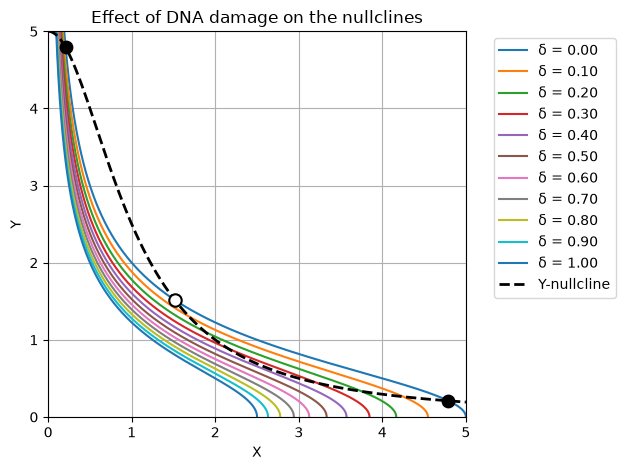

In [81]:
# Question 7B

beta = 5.0
n = 2

def nullcline_X_damage(Y, delta):
    return beta / ((1 + delta) * (1 + Y**n))


X_vals = np.linspace(0, 5, 500)
Y_vals = np.linspace(0, 5, 500)

# Only 10 delta values are shown on the graph
delta_plot = np.linspace(0, 1, 11)

for delta in delta_plot:
    plt.plot(
        nullcline_X_damage(Y_vals, delta),
        Y_vals,
        label=f'δ = {delta:.2f}'
    )

# Y-nullcline stays the same
plt.plot(
    X_vals,
    nullcline_Y(X_vals),
    'k--',
    linewidth=2,
    label='Y-nullcline'
)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Effect of DNA damage on the nullclines')
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

# Reference fixed points for the undamaged system (delta = 0)
fp_X = np.array([x1, x2, x3])
fp_Y = beta / (1 + fp_X**n)

# Stable fixed points
plt.scatter(
    fp_X[[0, 2]],
    fp_Y[[0, 2]],
    s=80,
    c='black',
    zorder=5,
    label='Stable fixed points (δ = 0)'
)

# Unstable fixed point
plt.scatter(
    fp_X[1],
    fp_Y[1],
    s=80,
    facecolors='white',
    edgecolors='black',
    linewidths=1.5,
    zorder=5,
    label='Unstable fixed point (δ = 0)'
)


# Use many delta values to find the critical value accurately
delta_scan = np.linspace(0, 1, 101)

def find_fixed_points_damage(delta):

    def difference(X):
        Y = beta / (1 + X**n)
        X_new = beta / ((1 + delta) * (1 + Y**n))
        return X_new - X

    roots = []

    for i in range(len(X_vals) - 1):
        if difference(X_vals[i]) * difference(X_vals[i + 1]) < 0:
            root = brentq(difference, X_vals[i], X_vals[i + 1])

            if not roots or abs(root - roots[-1]) > 0.01:
                roots.append(root)

    return roots

delta_scan = np.linspace(0, 1, 101)

for delta in delta_scan:
    roots = find_fixed_points_damage(delta)

    if len(roots) < 3:
        delta_star = delta
        print("Critical delta =", round(delta_star, 2))
        break



**Question 7B**


The critical damage level is approximately
$$
\delta^* = 0.36.
$$

Below this value, the system still has the lysogenic fixed point. As $\delta$ increases, the lysogenic stable fixed point and the unstable middle fixed point approach each other and eventually disappear.

For $\delta > \delta^*$, lysogeny is no longer a possible steady state, so the system moves toward the lytic state, where $X$ is low and $Y$ is high.


Shortest pulse causing lysis = 3.4


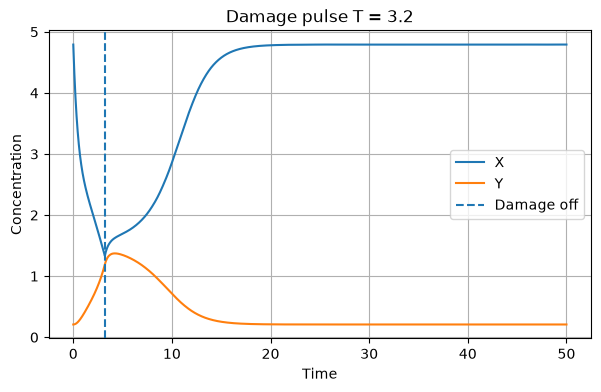

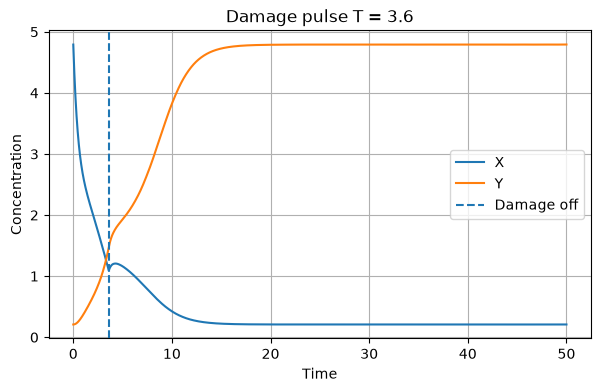

In [86]:
# Question 7C

def system_damage(t, z, delta):
    X, Y = z

    dXdt = beta / (1 + Y**n) - (1 + delta) * X
    dYdt = beta / (1 + X**n) - Y

    return [dXdt, dYdt]

X_lys = x3
Y_lys = beta / (1 + X_lys**n)

initial_lysogeny = [X_lys, Y_lys]

def damage_pulse(T):

    # Damage on
    sol1 = solve_ivp(
        lambda t, z: system_damage(t, z, 1),
        [0, T],
        initial_lysogeny,
        t_eval=np.linspace(0, T, 5000)
    )

    state_after_damage = [
        sol1.y[0][-1],
        sol1.y[1][-1]
    ]

    # Damage off
    sol2 = solve_ivp(
        lambda t, z: system_damage(t, z, 0),
        [T, 50],
        state_after_damage,
        t_eval=np.linspace(T, 50, 5000)
    )

    return sol1, sol2

for T in np.arange(0.1, 10.1, 0.1):

    sol1, sol2 = damage_pulse(T)

    X_final = sol2.y[0][-1]
    Y_final = sol2.y[1][-1]

    if Y_final > X_final:
        T_star = T
        print("Shortest pulse causing lysis =", round(T_star, 1))
        break

T_short = T_star - 0.2
T_long = T_star + 0.2

for T in [T_short, T_long]:

    sol1, sol2 = damage_pulse(T)

    time = np.concatenate([sol1.t, sol2.t])
    X = np.concatenate([sol1.y[0], sol2.y[0]])
    Y = np.concatenate([sol1.y[1], sol2.y[1]])

    plt.figure(figsize=(7, 4))

    plt.plot(time, X, label='X')
    plt.plot(time, Y, label='Y')

    plt.axvline(T, linestyle='--', label='Damage off')

    plt.xlabel('Time')
    plt.ylabel('Concentration')
    plt.title(f'Damage pulse T = {T:.1f}')
    plt.grid()
    plt.legend()

    plt.show()

**Question 7C**
- Whether the cell goes back to lysogeny depends on T. For these specific conditions, the shortest time T for which the cell returns to lysis even after changing $\delta$ to 0, is 3.4. 

- At T=3.2, the cell goes back to lysogeny.

- At T=3.6, the cell does not go back to lysogeny, and returns to lysis. 

- Therefore, for any value of T exceeding 3.4, the cell returns to lysis.

- In lecture 3, we discussed a gene that positively autoregulated itself. When a sufficiently high signal s was applied for a sufficiently long time t, the cell retains memory of its initial state (producing protein X) even after the signal is removed. 
In this specific example, the gene cI is repressed by Cro, so the concept remains the same, but the result differs because of the mode of repression. 

---
## Part IV: The same switch with a few molecules

> **From concentrations to molecules** (as in Lectures 2 and 4). Let $N_X$ and $N_Y$ be the
> numbers of cI and Cro molecules in one cell of volume $V$, so that $X = N_X/V$ and $Y = N_Y/V$.
> The four reactions and their rates are
>
> | reaction | change | rate |
> |---|---|---|
> | X is made | $N_X \to N_X + 1$ | $V\,\beta_X/(1 + (N_Y/V)^n)$ |
> | X is removed | $N_X \to N_X - 1$ | $(1+\delta)\, N_X$ |
> | Y is made | $N_Y \to N_Y + 1$ | $V\,\beta/(1 + (N_X/V)^n)$ |
> | Y is removed | $N_Y \to N_Y - 1$ | $N_Y$ |
>
> Production is multiplied by $V$, removal is not (first order, the same per-molecule rate in a
> large or a small cell). With $V = 10$ lysogeny holds about 48 cI molecules per cell.
> Simulate with the Gillespie algorithm.

### Question 8. One cell, and a newly infected cell
Use $V = 10$, $\beta_X = \beta = 5$ and no damage ($\delta = 0$).
(a) Simulate one cell starting from lysogeny ($N_X = 48$, $N_Y = 2$) up to $t = 100$, and plot
$N_X(t)$ and $N_Y(t)$. Does it stay in lysogeny?
(b) Now simulate a newly infected cell, $N_X = N_Y = 0$, up to $t = 100$. Repeat five times
(each run uses different random numbers) and plot $N_X - N_Y$ for the five runs on one graph.
Where does each cell go? Compare with Question 6c: what does noise do that the deterministic
model could not?

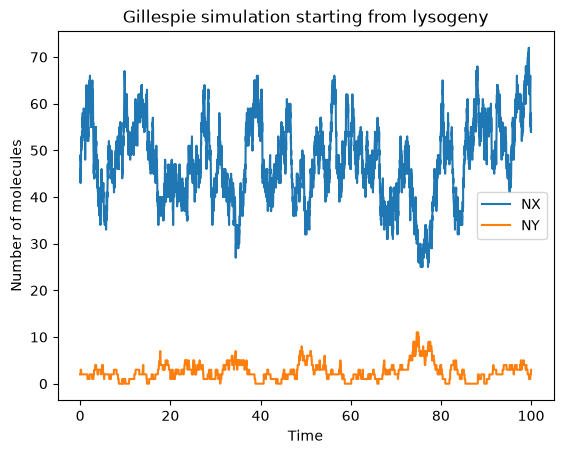

In [106]:
# Question 8 - Gillespie function

V = 10
beta_X = beta = 5.0
n = 2
delta = 0

def gillespie_toggle(NX0, NY0, t_end=100):

    NX = NX0
    NY = NY0
    t = 0

    # lists to store the information
    times = [t]
    NX_values = [NX]
    NY_values = [NY]

    while t < t_end:

        rate_Xproduction = V * beta_X / (1 + (NY / V)**n)
        rate_Xremoval = (1 + delta) * NX
        rate_Yproduction = V * beta / (1 + (NX / V)**n)
        rate_Yremoval = NY

        total_rate = (
            rate_Xproduction
            + rate_Xremoval
            + rate_Yproduction
            + rate_Yremoval
        )

        # determine the time jump between 2 reactions
        dt = np.random.exponential(1 / total_rate)
        t = t + dt

        # choose which reaction will happen randomly
        random_number = np.random.random() * total_rate

        if random_number < rate_Xproduction:
            NX += 1

        elif random_number < rate_Xproduction + rate_Xremoval:
            NX -= 1

        elif random_number < rate_Xproduction + rate_Xremoval + rate_Yproduction:
            NY += 1

        else:
            NY -= 1

        # updating the lists
        times.append(t)
        NX_values.append(NX)
        NY_values.append(NY)

    return np.array(times), np.array(NX_values), np.array(NY_values)

# Question 8A

times, NX_values, NY_values = gillespie_toggle(48, 2)

plt.plot(times, NX_values, label='NX')
plt.plot(times, NY_values, label='NY')

plt.xlabel('Time')
plt.ylabel('Number of molecules')
plt.title('Gillespie simulation starting from lysogeny')
plt.legend()
plt.show()

**Question 8A**


The cell stays in the lysogenic state during the simulation. Even though the molecule numbers fluctuate because of stochastic events, $N_X$ remains high while $N_Y$ remains low.

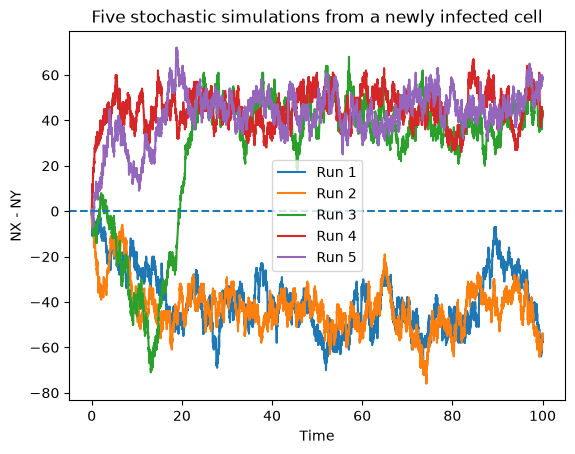

In [123]:
#Question 8B
plt.figure()

for run in range(5):

    times, NX_values, NY_values = gillespie_toggle(0, 0)

    difference = NX_values - NY_values

    plt.plot(times, difference, label=f'Run {run + 1}')

plt.axhline(0, linestyle='--')
plt.xlabel('Time')
plt.ylabel('NX - NY')
plt.title('Five stochastic simulations from a newly infected cell')
plt.legend()
plt.show()

**Question 8B**


In all five simulations, the cells do not stay in an intermediate state. They eventually move toward either lysogeny or lysis.


Since the Gillespie simulation is stochastic, repeating the simulations with different random events could give a different result.

Compared with the deterministic model in Question 6C, this model can take into account the small molecular fluctuations that can normally occur in the cell. In the deterministic model, starting from $X=Y=0$ kept the system perfectly symmetric and led it toward the unstable fixed point. Here, the random fluctuations break this symmetry and allow the cell to choose between lysogeny and lysis.

### Question 9. How long does the memory last?
Without any damage, a lysogen occasionally switches to lysis on its own. This happens in real
lysogens too, and is called spontaneous induction. In Question 8, with $\beta = 5$, you probably
did not see it. Here we keep $V = 10$ and make both promoters weaker: $\beta = 2.5$, $3$ and $3.5$,
the same for X and Y.

For each $\beta$:
1. find the lysogenic fixed point $(X^\ast, Y^\ast)$ with your code of Question 4;
2. simulate one cell, starting from $N_X = V X^\ast$, $N_Y = V Y^\ast$ (rounded), up to
   $t = 5000$, and record $N_X$, $N_Y$ every $0.5$ time units;
3. count the switches with this rule: a lysogen has switched to lysis when $N_Y$ reaches
   $0.8\,V X^\ast$ (80% of the high level), and a lytic cell has switched back when $N_X$ does;
4. compute the **mean stay**, the mean time between two switches.

Plot the mean stay against $\beta$, with a logarithmic vertical axis. How does it change? Why does
a stronger promoter give a longer memory? (There are two reasons: think of the rate plot, and of
the number of molecules.) What does your result suggest for $\beta = 5$, and for the cell of
Question 8?

beta = 2.5
Starting NX = 20
Starting NY = 5
Number of switches = 375
Mean stay = 13.26176301155654

beta = 3.0
Starting NX = 26
Starting NY = 4
Number of switches = 108
Mean stay = 46.33942093567834

beta = 3.5
Starting NX = 32
Starting NY = 3
Number of switches = 45
Mean stay = 111.76793367217611



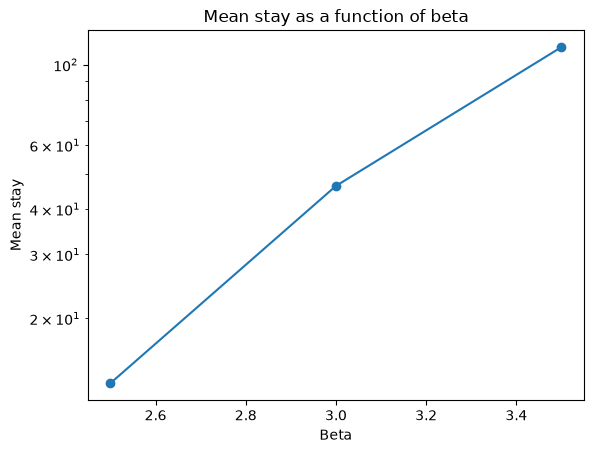

In [ ]:
# Question 9

beta_values = [2.5, 3.0, 3.5]
mean_stays = []

for beta in beta_values:

    beta_X = beta

    # Question 9-1
    x_vals = np.linspace(0, beta, 500)
    roots = []

    for i in range(len(x_vals) - 1):

        if G(x_vals[i]) * G(x_vals[i + 1]) < 0:

            root = brentq(
                G,
                x_vals[i],
                x_vals[i + 1]
            )

            roots.append(root)

    X_star = max(roots)
    Y_star = beta / (1 + X_star**n)


    # Question 9-2
    NX0 = round(V * X_star)
    NY0 = round(V * Y_star)

    times, NX_values, NY_values = gillespie_toggle(
        NX0,
        NY0,
        t_end=5000
    )

    print("beta =", beta)
    print("Starting NX =", NX0)
    print("Starting NY =", NY0)


    # Question 9-3
    threshold = 0.8 * V * X_star

    state = 'lysogen'
    switch_times = []

    for i in range(len(times)):

        if state == 'lysogen' and NY_values[i] >= threshold:

            switch_times.append(times[i])
            state = 'lytic'

        elif state == 'lytic' and NX_values[i] >= threshold:

            switch_times.append(times[i])
            state = 'lysogen'


    # Question 9-4
    if len(switch_times) >= 2:

        stays = np.diff(switch_times)
        mean_stay = np.mean(stays)

    else:

        mean_stay = np.nan

    mean_stays.append(mean_stay)

    print("Number of switches =", len(switch_times))
    print("Mean stay =", mean_stay)
    print()


# Plot after all 3 beta values are finished
plt.plot(beta_values, mean_stays, marker='o')
plt.yscale('log')

plt.xlabel('Beta')
plt.ylabel('Mean stay')
plt.title('Mean stay as a function of beta')

plt.show()
    




**Question 9**
  
- The mean stay increases with beta. 

- A stronger promoter will have a larger $\beta$. Hence, the mean stay will be longer. If we start off with a certain quantity of protein X and at a particular time, production of X is switched off, the cell will take a longer time to switch to lysis in case of a larger $\beta$. This is because a larger $\beta$ means that a large number of molecules of X will continue to repress protein Y until they are eventually degraded. This will increase the stay time in lysogeny and vice-versa. 

- For $\beta$=5, the mean stay will be longer than 100. This could also explain the behaviour of the cell in Question 8, in which, even in the case of a stochastic simulation, the cell tends to stay in its initial state (lysis/lysogeny). Running the simulation multiple times results in an occasional switch. 

---
## Bonus question: designing a toggle switch

*Optional: it can raise the mark, but it is not needed for full marks.*

Gardner, Cantor and Collins (2000) asked which promoter strengths give a working switch. In the
plane $(\beta_X, \beta_Y)$, between 0 and 10, colour the region where the circuit is bistable, for
$n = 2$ and for $n = 3$. Why must the two promoters be "balanced"? What does a larger $n$ buy?
Where does the damage of Question 7 move a cell in this plane?